
# UP-Fall Camera2 — LSTM Baseline (No Augmentation)

- Input: `(30, 51)`
- Dataset: `/kaggle/input/datasets/anhoa1/upfall-camera2-processing`
- Train/Val/Test giữ nguyên subject split
- **Không augmentation**
- Có class weight
- Tune threshold trên validation theo F2
- Đánh giá đầy đủ trên test


In [1]:

# ============================================================
# 1. IMPORTS + REPRODUCIBILITY
# ============================================================

import os
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve,
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:

# ============================================================
# 2. CONFIG
# ============================================================

DATA_DIR = Path("/kaggle/input/datasets/anhoa1/upfall-camera2-processing")
OUTPUT_DIR = Path("/kaggle/working/upfall_lstm_baseline")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = DATA_DIR / "upfall_train.npz"
VAL_PATH   = DATA_DIR / "upfall_val.npz"
TEST_PATH  = DATA_DIR / "upfall_test.npz"
CLASS_WEIGHT_PATH = DATA_DIR / "class_weight.json"

SEQ_LEN = 30
NUM_KEYPOINTS = 17
NUM_FEATURES = 51

BATCH_SIZE = 128
EPOCHS = 100
INITIAL_LR = 1e-3

print("DATA_DIR exists:", DATA_DIR.exists())
for p in [TRAIN_PATH, VAL_PATH, TEST_PATH, CLASS_WEIGHT_PATH]:
    print(p.name, "->", p.exists())


DATA_DIR exists: True
upfall_train.npz -> True
upfall_val.npz -> True
upfall_test.npz -> True
class_weight.json -> True


In [3]:

# ============================================================
# 3. LOAD DATA
# ============================================================

def load_xy(path):
    d = np.load(path, allow_pickle=True)
    if "X" not in d.files or "y" not in d.files:
        raise KeyError(f"{path.name} thiếu X/y. Keys: {d.files}")

    X = d["X"].astype(np.float32)
    y = d["y"].astype(np.int32).reshape(-1)
    return X, y, d

X_train, y_train, train_npz = load_xy(TRAIN_PATH)
X_val, y_val, val_npz = load_xy(VAL_PATH)
X_test, y_test, test_npz = load_xy(TEST_PATH)

print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)


Train: (10407, 30, 51) (10407,)
Val  : (2046, 30, 51) (2046,)
Test : (4786, 30, 51) (4786,)


In [4]:

# ============================================================
# 4. VALIDATE DATA
# ============================================================

def check_split(name, X, y):
    labels, counts = np.unique(y, return_counts=True)
    print(f"\n{name}")
    print("Shape:", X.shape, y.shape)
    print("Labels:", dict(zip(labels.tolist(), counts.tolist())))
    print("NaN:", int(np.isnan(X).sum()))
    print("Inf:", int(np.isinf(X).sum()))

    assert X.ndim == 3
    assert X.shape[1:] == (SEQ_LEN, NUM_FEATURES)
    assert len(X) == len(y)
    assert np.isnan(X).sum() == 0
    assert np.isinf(X).sum() == 0
    assert set(np.unique(y)).issubset({0, 1})

check_split("TRAIN", X_train, y_train)
check_split("VAL", X_val, y_val)
check_split("TEST", X_test, y_test)

print("\nDataset validation PASSED.")



TRAIN
Shape: (10407, 30, 51) (10407,)
Labels: {0: 10093, 1: 314}
NaN: 0
Inf: 0

VAL
Shape: (2046, 30, 51) (2046,)
Labels: {0: 1990, 1: 56}
NaN: 0
Inf: 0

TEST
Shape: (4786, 30, 51) (4786,)
Labels: {0: 4686, 1: 100}
NaN: 0
Inf: 0

Dataset validation PASSED.


In [5]:

# ============================================================
# 5. CLASS WEIGHT (ORIGINAL TRAIN)
# ============================================================

if CLASS_WEIGHT_PATH.exists():
    with open(CLASS_WEIGHT_PATH, "r", encoding="utf-8") as f:
        raw = json.load(f)
    class_weight = {int(k): float(v) for k, v in raw.items()}
else:
    n0 = int(np.sum(y_train == 0))
    n1 = int(np.sum(y_train == 1))
    n = len(y_train)
    class_weight = {
        0: n / (2.0 * n0),
        1: n / (2.0 * n1),
    }

print("Class weight:", class_weight)
print("Train No Fall:", int(np.sum(y_train == 0)))
print("Train Fall   :", int(np.sum(y_train == 1)))


Class weight: {0: 0.5155553353809571, 1: 16.571656050955415}
Train No Fall: 10093
Train Fall   : 314


In [6]:

# ============================================================
# BUILD LSTM MODEL
# ============================================================

tf.keras.backend.clear_session()

inputs = keras.Input(
    shape=(SEQ_LEN, NUM_FEATURES),
    name="skeleton_sequence"
)

x = layers.Bidirectional(
    layers.LSTM(
        64,
        return_sequences=True,
        dropout=0.20
    )
)(inputs)

x = layers.Dropout(0.30)(x)

x = layers.LSTM(
    32,
    return_sequences=False,
    dropout=0.20
)(x)

x = layers.Dense(
    32,
    activation="relu"
)(x)

x = layers.Dropout(0.30)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="fall_probability"
)(x)

model = keras.Model(
    inputs,
    outputs,
    name="upfall_lstm"
)

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=INITIAL_LR
    ),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="roc_auc"),
        keras.metrics.AUC(curve="PR", name="pr_auc"),
    ],
)

model.summary()


I0000 00:00:1792417527.291099      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792417527.294938      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "upfall_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ skeleton_sequence (InputLayer)  │ (None, 30, 51)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 30, 128)        │        59,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        20,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fall_probability (Dense)        │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,089 (316.75 KB)

 Trainable params: 81,089 (316.75 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:

# ============================================================
# CALLBACKS
# ============================================================

BEST_MODEL_PATH = OUTPUT_DIR / "best_lstm_baseline.keras"

callbacks = [
    keras.callbacks.ModelCheckpoint(
        BEST_MODEL_PATH,
        monitor="val_pr_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_pr_auc",
        mode="max",
        patience=15,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=6,
        min_lr=1e-6,
        verbose=1
    ),
]


In [8]:

# ============================================================
# TRAIN
# ============================================================

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1
)

print("Training finished.")
print("Best model:", BEST_MODEL_PATH)


Epoch 1/100
81/82 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7907 - loss: 0.5939 - pr_auc: 0.1189 - precision: 0.0790 - recall: 0.5686 - roc_auc: 0.7525
Epoch 1: val_pr_auc improved from None to 0.43424, saving model to /kaggle/working/upfall_lstm_baseline/best_lstm_baseline.keras

Epoch 1: finished saving model to /kaggle/working/upfall_lstm_baseline/best_lstm_baseline.keras
82/82 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.8088 - loss: 0.5248 - pr_auc: 0.2235 - precision: 0.1002 - recall: 0.6688 - roc_auc: 0.8262 - val_accuracy: 0.9022 - val_loss: 0.2501 - val_pr_auc: 0.4342 - val_precision: 0.1727 - val_recall: 0.6786 - val_roc_auc: 0.9188 - learning_rate: 0.0010
Epoch 2/100
80/82 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8801 - loss: 0.3443 - pr_auc: 0.3926 - precision: 0.1784 - recall: 0.8348 - roc_auc: 0.9279
Epoch 2: val_pr_auc improved from 0.43424 to 0.47936, saving model to /kaggle/working/upfall_lstm_baseline/best_lstm_baseline.keras

Epoch 2: finished saving 

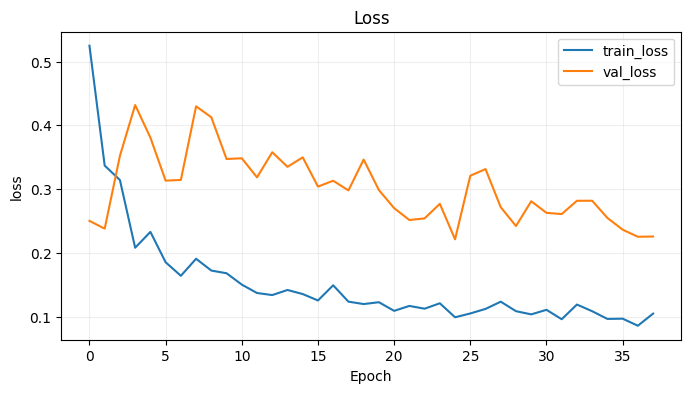

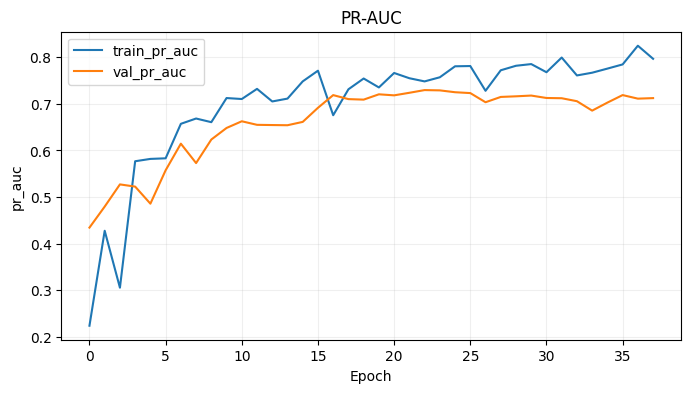

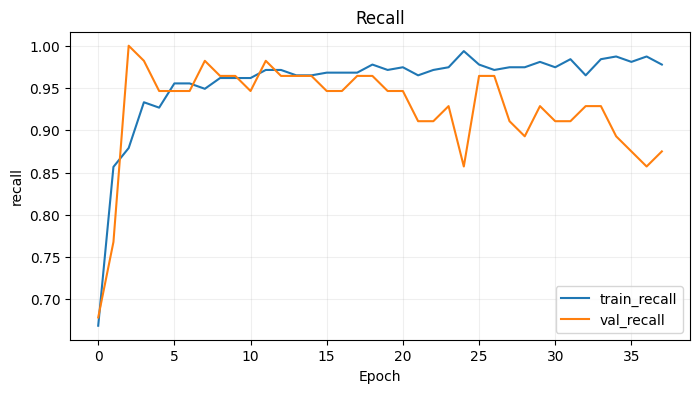

In [9]:

# ============================================================
# TRAINING CURVES
# ============================================================

history_df = pd.DataFrame(history.history)
history_df.to_csv(
    OUTPUT_DIR / "training_history.csv",
    index=False
)

def plot_history(metric, title):
    plt.figure(figsize=(8, 4))
    plt.plot(history_df[metric], label=f"train_{metric}")

    val_metric = f"val_{metric}"
    if val_metric in history_df.columns:
        plt.plot(history_df[val_metric], label=val_metric)

    plt.xlabel("Epoch")
    plt.ylabel(metric)
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

plot_history("loss", "Loss")
plot_history("pr_auc", "PR-AUC")
plot_history("recall", "Recall")


In [10]:

# ============================================================
# LOAD BEST MODEL
# ============================================================

model = keras.models.load_model(
    BEST_MODEL_PATH
)

val_prob = model.predict(
    X_val,
    batch_size=BATCH_SIZE,
    verbose=0
).reshape(-1)

print("Validation probabilities:", val_prob.shape)


Validation probabilities: (2046,)


In [11]:

# ============================================================
# THRESHOLD TUNING ON VALIDATION
# ============================================================

rows = []

for threshold in np.arange(0.05, 0.991, 0.01):
    pred = (val_prob >= threshold).astype(np.int32)

    precision = precision_score(
        y_val, pred, zero_division=0
    )
    recall = recall_score(
        y_val, pred, zero_division=0
    )
    f1 = f1_score(
        y_val, pred, zero_division=0
    )
    f2 = fbeta_score(
        y_val, pred, beta=2, zero_division=0
    )

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        pred,
        labels=[0, 1]
    ).ravel()

    rows.append({
        "threshold": float(threshold),
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "f2": float(f2),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    })

threshold_df = pd.DataFrame(rows)

best_row = (
    threshold_df
    .sort_values(
        ["f2", "recall", "precision"],
        ascending=False
    )
    .iloc[0]
)

BEST_THRESHOLD = float(best_row["threshold"])

print("Best threshold by validation F2:", BEST_THRESHOLD)
display(best_row.to_frame().T)

threshold_df.to_csv(
    OUTPUT_DIR / "validation_threshold_search.csv",
    index=False
)

with open(
    OUTPUT_DIR / "best_threshold.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        {
            "criterion": "max_validation_f2",
            "threshold": BEST_THRESHOLD,
            "validation_metrics": {
                k: (
                    int(v)
                    if k in {"tn", "fp", "fn", "tp"}
                    else float(v)
                )
                for k, v in best_row.to_dict().items()
            },
        },
        f,
        indent=2
    )


Best threshold by validation F2: 0.9300000000000002


,threshold,precision,recall,f1,f2,tn,fp,fn,tp
88,0.93,0.505882,0.767857,0.609929,0.695793,1948.0,42.0,13.0,43.0


In [12]:

# ============================================================
# EVALUATION FUNCTION
# ============================================================

def evaluate_binary(y_true, prob, threshold):
    pred = (prob >= threshold).astype(np.int32)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        pred,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    metrics = {
        "threshold": float(threshold),
        "accuracy": float(accuracy_score(y_true, pred)),
        "precision": float(precision_score(y_true, pred, zero_division=0)),
        "recall": float(recall_score(y_true, pred, zero_division=0)),
        "specificity": float(specificity),
        "f1": float(f1_score(y_true, pred, zero_division=0)),
        "f2": float(fbeta_score(y_true, pred, beta=2, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, prob)),
        "pr_auc": float(average_precision_score(y_true, prob)),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }

    return metrics, pred


In [13]:

# ============================================================
# FINAL TEST EVALUATION
# ============================================================

test_prob = model.predict(
    X_test,
    batch_size=BATCH_SIZE,
    verbose=0
).reshape(-1)

test_metrics, test_pred = evaluate_binary(
    y_test,
    test_prob,
    BEST_THRESHOLD
)

print("FINAL LSTM BASELINE TEST METRICS")
print("=" * 60)

for k, v in test_metrics.items():
    if isinstance(v, float):
        print(f"{k:12s}: {v:.6f}")
    else:
        print(f"{k:12s}: {v}")

print("\nClassification report:")
print(
    classification_report(
        y_test,
        test_pred,
        target_names=["No Fall", "Fall"],
        digits=4,
        zero_division=0
    )
)

with open(
    OUTPUT_DIR / "test_metrics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(test_metrics, f, indent=2)


FINAL LSTM BASELINE TEST METRICS
threshold   : 0.930000
accuracy    : 0.978061
precision   : 0.483221
recall      : 0.720000
specificity : 0.983568
f1          : 0.578313
f2          : 0.655738
roc_auc     : 0.975807
pr_auc      : 0.599666
tn          : 4609
fp          : 77
fn          : 28
tp          : 72

Classification report:
              precision    recall  f1-score   support

     No Fall     0.9940    0.9836    0.9887      4686
        Fall     0.4832    0.7200    0.5783       100

    accuracy                         0.9781      4786
   macro avg     0.7386    0.8518    0.7835      4786
weighted avg     0.9833    0.9781    0.9802      4786



[[4609   77]
 [  28   72]]


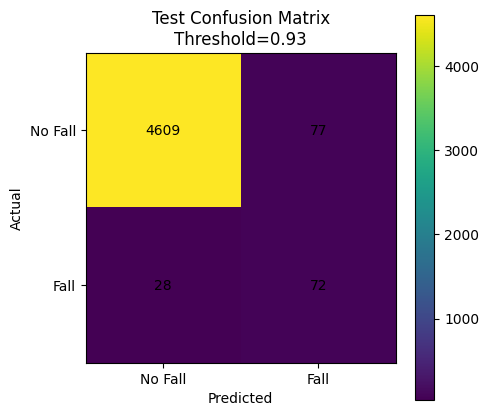

Fall thật: 100
TP: 72
FN (Fall -> No Fall): 28
FP (No Fall -> Fall): 77


In [14]:

# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
)

print(cm)

fig, ax = plt.subplots(figsize=(5, 5))
im = ax.imshow(cm)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["No Fall", "Fall"])
ax.set_yticklabels(["No Fall", "Fall"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(
    f"Test Confusion Matrix\nThreshold={BEST_THRESHOLD:.2f}"
)

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center"
        )

plt.colorbar(im)
plt.show()

print("Fall thật:", int(np.sum(y_test == 1)))
print("TP:", test_metrics["tp"])
print("FN (Fall -> No Fall):", test_metrics["fn"])
print("FP (No Fall -> Fall):", test_metrics["fp"])


In [15]:

# ============================================================
# SAVE TEST PREDICTIONS + FALL RECALL BY ACTIVITY
# ============================================================

pred_df = pd.DataFrame({
    "y_true": y_test.astype(int),
    "prob_fall": test_prob.astype(float),
    "y_pred": test_pred.astype(int),
})

for key in ["subject", "activity", "trial"]:
    if key in test_npz.files:
        pred_df[key] = test_npz[key]

pred_df["error_type"] = "correct"

pred_df.loc[
    (pred_df["y_true"] == 1)
    & (pred_df["y_pred"] == 0),
    "error_type"
] = "FN_fall_missed"

pred_df.loc[
    (pred_df["y_true"] == 0)
    & (pred_df["y_pred"] == 1),
    "error_type"
] = "FP_false_alarm"

pred_df.to_csv(
    OUTPUT_DIR / "test_predictions.csv",
    index=False
)

print(pred_df["error_type"].value_counts())

if "activity" in pred_df.columns:
    fall_only = pred_df[pred_df["y_true"] == 1].copy()

    activity_eval = (
        fall_only
        .groupby("activity")
        .agg(
            total_fall=("y_true", "size"),
            detected_fall=("y_pred", "sum")
        )
        .reset_index()
    )

    activity_eval["missed_fall"] = (
        activity_eval["total_fall"]
        - activity_eval["detected_fall"]
    )

    activity_eval["recall"] = (
        activity_eval["detected_fall"]
        / activity_eval["total_fall"]
    )

    display(activity_eval)

    activity_eval.to_csv(
        OUTPUT_DIR / "fall_recall_by_activity.csv",
        index=False
    )


error_type
correct           4681
FP_false_alarm      77
FN_fall_missed      28
Name: count, dtype: int64


,activity,total_fall,detected_fall,missed_fall,recall
0,1,20,13,7,0.650000
1,2,21,19,2,0.904762
2,3,18,15,3,0.833333
3,4,16,13,3,0.812500
4,5,25,12,13,0.480000


In [16]:

# ============================================================
# EXPORT KERAS + TFLITE
# ============================================================

FINAL_KERAS_PATH = OUTPUT_DIR / "lstm_baseline_final.keras"
model.save(FINAL_KERAS_PATH)
print("Saved:", FINAL_KERAS_PATH)

converter = tf.lite.TFLiteConverter.from_keras_model(model)

try:
    tflite_model = converter.convert()

    TFLITE_PATH = OUTPUT_DIR / "lstm_baseline.tflite"

    with open(TFLITE_PATH, "wb") as f:
        f.write(tflite_model)

    print("Saved TFLite:", TFLITE_PATH)
    print(
        "Size MB:",
        TFLITE_PATH.stat().st_size / 1024 / 1024
    )

except Exception as e:
    print(
        "TFLite export failed:",
        type(e).__name__,
        e
    )


Saved: /kaggle/working/upfall_lstm_baseline/lstm_baseline_final.keras
INFO:tensorflow:Assets written to: /tmp/tmp932x4i0s/assets


INFO:tensorflow:Assets written to: /tmp/tmp932x4i0s/assets


Saved artifact at '/tmp/tmp932x4i0s'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 30, 51), dtype=tf.float32, name='skeleton_sequence')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  132428223031312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132428223031504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132428223033424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132428223032080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132430938864144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132430978879696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132430938853584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132428223031696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132428223029776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132428223029968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13242822303188

W0000 00:00:1792417586.582030      49 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792417586.582069      49 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1792417586.605617      49 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
loc(callsite(fused["CudnnRNNV3:", "upfall_lstm_1/bidirectional_1/backward_lstm_1/CudnnRNNV3@__inference_function_55061"] at callsite(fused["StatefulPartitionedCall:", "StatefulPartitionedCall@__inference_signature_wrapper_55136"] at fused["StatefulPartitionedCall:", "StatefulPartitionedCall_1"]))): error: 'tf.CudnnRNNV3' op is neither a custom op nor a flex op
loc(callsite(fused["CudnnRNNV3:", "upfall_lstm_1/bidirectional_1/forward_lstm_1/CudnnRNNV3@__inference_function_55061"] at callsite(fused["StatefulPartitionedCall:", "StatefulPartitionedCall@__inference_signature_wrapper_55136"] at fused["StatefulPartitionedCall:", "StatefulPartitionedCall_1"]))): error: 'tf.CudnnRNNV3'

In [17]:

# ============================================================
# EXPERIMENT SUMMARY
# ============================================================

summary = {
    "model": "LSTM baseline",
    "augmentation": False,
    "input_shape": [SEQ_LEN, NUM_FEATURES],
    "train_samples": int(len(X_train)),
    "val_samples": int(len(X_val)),
    "test_samples": int(len(X_test)),
    "train_fall": int(np.sum(y_train == 1)),
    "val_fall": int(np.sum(y_val == 1)),
    "test_fall": int(np.sum(y_test == 1)),
    "class_weight": {
        str(k): float(v)
        for k, v in class_weight.items()
    },
    "best_threshold": float(BEST_THRESHOLD),
    "test_metrics": test_metrics,
}

with open(
    OUTPUT_DIR / "experiment_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))

print("\nOUTPUT FILES")
print("=" * 60)

for p in sorted(OUTPUT_DIR.iterdir()):
    print(
        f"{p.name:40s}",
        f"{p.stat().st_size / 1024 / 1024:.2f} MB"
    )


{
  "model": "LSTM baseline",
  "augmentation": false,
  "input_shape": [
    30,
    51
  ],
  "train_samples": 10407,
  "val_samples": 2046,
  "test_samples": 4786,
  "train_fall": 314,
  "val_fall": 56,
  "test_fall": 100,
  "class_weight": {
    "0": 0.5155553353809571,
    "1": 16.571656050955415
  },
  "best_threshold": 0.9300000000000002,
  "test_metrics": {
    "threshold": 0.9300000000000002,
    "accuracy": 0.9780610112829085,
    "precision": 0.48322147651006714,
    "recall": 0.72,
    "specificity": 0.9835680751173709,
    "f1": 0.5783132530120482,
    "f2": 0.6557377049180327,
    "roc_auc": 0.9758066581306017,
    "pr_auc": 0.599666478449505,
    "tn": 4609,
    "fp": 77,
    "fn": 28,
    "tp": 72
  }
}

OUTPUT FILES
best_lstm_baseline.keras                 0.98 MB
best_threshold.json                      0.00 MB
experiment_summary.json                  0.00 MB
fall_recall_by_activity.csv              0.00 MB
lstm_baseline_final.keras                0.98 MB
test_metrics

## Local deployment bundle
Cell cuối lưu model, TFLite, threshold, config và ví dụ inference thành một ZIP.

In [18]:

# ============================================================
# LOCAL DEPLOYMENT EXPORT
# ============================================================

import json, shutil
from pathlib import Path

DEPLOY_DIR = OUTPUT_DIR / "deploy_bundle"
DEPLOY_DIR.mkdir(parents=True, exist_ok=True)

artifact_names = [
    "best_lstm_baseline.keras",
    "lstm_baseline_final.keras",
    "lstm_baseline.tflite",
    "best_threshold.json",
    "experiment_summary.json",
    "test_metrics.json",
]

for name in artifact_names:
    src = OUTPUT_DIR / name
    if src.exists():
        shutil.copy2(src, DEPLOY_DIR / name)

deployment_config = {
    "model_name": "LSTM baseline",
    "input_shape": [30, 51],
    "sequence_length": 30,
    "num_keypoints": 17,
    "feature_order_per_keypoint": ["x", "y", "visibility"],
    "keypoint_names": ['nose', 'left_shoulder', 'right_shoulder', 'left_elbow', 'right_elbow', 'left_wrist', 'right_wrist', 'left_hip', 'right_hip', 'left_knee', 'right_knee', 'left_ankle', 'right_ankle', 'left_heel', 'right_heel', 'left_foot_index', 'right_foot_index'],
    "label_mapping": {"0": "No Fall", "1": "Fall"},
    "threshold": float(BEST_THRESHOLD),
    "threshold_source": "validation max F2",
    "input_dtype": "float32",
    "output": "Fall probability",
    "preprocessing_contract": [
        "Use the same MediaPipe 17-keypoint mapping as training preprocessing.",
        "Use the same missing-data interpolation as training preprocessing.",
        "Use the exact same normalize_skeleton() used to build the NPZ dataset.",
        "Do not add a new scaler unless training used it.",
        "Feed exactly 30 consecutive preprocessed frames.",
        "Apply the saved threshold to the Fall probability."
    ]
}

with open(DEPLOY_DIR / "deployment_config.json", "w", encoding="utf-8") as f:
    json.dump(deployment_config, f, indent=2, ensure_ascii=False)

inference_py = """import json
import numpy as np
import tensorflow as tf
from pathlib import Path

HERE = Path(__file__).resolve().parent
cfg = json.load(open(HERE / "deployment_config.json", "r", encoding="utf-8"))
threshold = float(cfg["threshold"])

model_path = next(HERE.glob("*.tflite"))
interpreter = tf.lite.Interpreter(model_path=str(model_path))
interpreter.allocate_tensors()

inp = interpreter.get_input_details()[0]
out = interpreter.get_output_details()[0]

def predict_preprocessed(sequence_30x51):
    x = np.asarray(sequence_30x51, dtype=np.float32)
    if x.shape != (30, 51):
        raise ValueError(f"Expected (30,51), got {x.shape}")
    interpreter.set_tensor(inp["index"], x[None, ...])
    interpreter.invoke()
    prob = float(interpreter.get_tensor(out["index"]).reshape(-1)[0])
    label = int(prob >= threshold)
    return {
        "prob_fall": prob,
        "label": label,
        "class_name": "Fall" if label else "No Fall",
    }
"""

with open(DEPLOY_DIR / "inference_tflite_example.py", "w", encoding="utf-8") as f:
    f.write(inference_py)

readme = f"""UP-Fall local deployment bundle
Model: {deployment_config['model_name']}
Input: (30,51) float32
Threshold: {deployment_config['threshold']}

Use the .tflite file for lightweight local inference.
Use .keras if you want TensorFlow/Keras inference or further fine-tuning.

IMPORTANT:
For raw webcam/video, reproduce the exact preprocessing used for the NPZ:
MediaPipe -> 17 keypoints -> interpolation -> exact normalize_skeleton()
-> rolling 30-frame buffer -> model -> threshold.
"""

with open(DEPLOY_DIR / "README_DEPLOY.txt", "w", encoding="utf-8") as f:
    f.write(readme)

DEPLOY_ZIP = OUTPUT_DIR / "upfall_lstm_baseline_LOCAL_DEPLOY.zip"
shutil.make_archive(
    str(DEPLOY_ZIP.with_suffix("")),
    "zip",
    root_dir=DEPLOY_DIR
)

print("DEPLOY ZIP:", DEPLOY_ZIP)
print("FILES:")
for p in sorted(DEPLOY_DIR.iterdir()):
    print(" -", p.name)


DEPLOY ZIP: /kaggle/working/upfall_lstm_baseline/upfall_lstm_baseline_LOCAL_DEPLOY.zip
FILES:
 - README_DEPLOY.txt
 - best_lstm_baseline.keras
 - best_threshold.json
 - deployment_config.json
 - experiment_summary.json
 - inference_tflite_example.py
 - lstm_baseline_final.keras
 - test_metrics.json
